<a href="https://colab.research.google.com/github/DianaBarradasSanchez/Simulaci-n-ll/blob/main/Algoritmo_MCMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelado Epidemiológico SIR y Estimación de Parámetros mediante MCMC

Este cuaderno documenta el proceso de modelado de un brote de influenza en un internado utilizando el **modelo epidemiológico SIR** ($S$: Susceptibles, $I$: Infectados, $R$: Recuperados). La estimación de los parámetros de transmisión ($a$) y recuperación ($b$) se realiza a través del **algoritmo de Metropolis-Hastings (MCMC)** optimizando la función de ajuste por mínimos cuadrados.

---

## 1. Definición de Datos Observados

Definimos los datos reales del brote registrados durante 14 días y las condiciones iniciales del sistema epidemiológico:
* $S_0 = 762$ individuos susceptibles
* $I_0 = 1$ individuo infectado
* $R_0 = 0$ individuos recuperados

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Datos del problema
t_data = np.arange(15)
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

S0, I0, R0 = 762, 1, 0
y0 = [S0, I0, R0]



## 2. Visualización de los Datos Reales

Visualizamos la serie de tiempo de los datos observados para comprender la dinámica del contagio y la altura del pico epidémico.

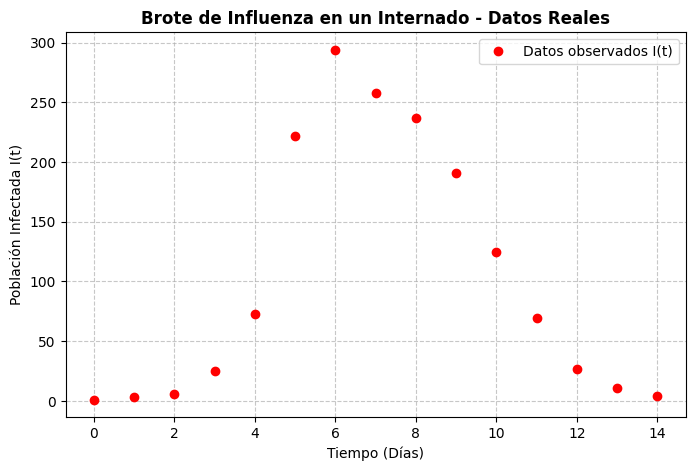

In [2]:

plt.figure(figsize=(8, 5))
plt.plot(t_data, I_data, 'ro', markersize=6, label='Datos observados I(t)')


plt.title('Brote de Influenza en un Internado - Datos Reales', fontsize=12, fontweight='bold')
plt.xlabel('Tiempo (Días)', fontsize=10)
plt.ylabel('Población Infectada I(t)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 3. Formulación y Solución Numérica del Modelo SIR

El modelo SIR se describe mediante el siguiente sistema de ecuaciones diferenciales ordinarias (EDOs):

$$\frac{dS}{dt} = -a \cdot S \cdot I$$

$$\frac{dI}{dt} = a \cdot S \cdot I - b \cdot I$$

$$\frac{dR}{dt} = b \cdot I$$

Donde $a$ es la tasa de transmisión por contacto y $b$ es la tasa de recuperación.

In [4]:
# solución numérica del modelo SIR
def sir_model(y, t, a, b):
  """ Sistema de EDOs
  y: vector de variables
  t: tiempo
  """
  S, I, R = y
  dS_dt = -a * S * I
  dI_dt = a * S * I - b * I #cambio en infectados
  dR_dt = b * I             #cambio en recuperados
  return [dS_dt, dI_dt, dR_dt]

def solve_sir(a, b, time_points):
    """Resuelve el modelo SIR con parámetros a y b."""
    y0 = [762, 1, 0]
    sol = odeint(sir_model, y0, time_points, args=(a, b))
    return sol[:, 1]


## 4. Definición de la Función Objetivo ($\chi^2$ / Suma de Errores al Cuadrado)

Para evaluar qué tan bien un par de parámetros $(a, b)$ reproduce los datos observados, calculamos la suma de residuos al cuadrado:

$$\chi^2(a, b) = \sum_{i} \left( I_{\text{datos}}(t_i) - I_{\text{modelo}}(t_i; a, b) \right)^2$$

In [6]:
# 4. Plantear un ajuste por mínimos cuadrados
def chi_squared(a, b):
    I_model = solve_sir(a, b, t_data)
    # Suma de los residuos al cuadrado (función objetivo)
    return np.sum((I_data - I_model)**2)


## 5. Estimación de Parámetros mediante MCMC (Algoritmo de Metropolis-Hastings)

El método de Cadena de Markov Monte Carlo (MCMC) permite explorar el espacio de parámetros $(a, b)$ mediante una caminata aleatoria. En cada paso:
1. Se proponen nuevos valores $a_{\text{prop}}$ y $b_{\text{prop}}$ muestreando distribuciones normales centradas en los valores actuales.
2. Se verifica la viabilidad física ($a > 0, b > 0$).
3. Se acepta el nuevo estado si reduce el error $\chi^2$, o con una probabilidad dependiente de la razón de verosimilitud $e^{-\frac{1}{2}\Delta\chi^2}$ si el error aumenta.

In [10]:
# 5. Usar el método MCMC (Metropolis-Hastings)
def metropolis_hastings(iters=5000):
    # Valores semilla cercanos a los de la literatura (a ≈ 0.00218, b ≈ 0.4485)
    current_a, current_b = 0.002, 0.4
    current_chi2 = chi_squared(current_a, current_b)

    samples = []

    for i in range(iters):
        # Caminata aleatoria (distribución propuesta)
        prop_a = np.random.normal(current_a, 0.0001)
        prop_b = np.random.normal(current_b, 0.01)

        # Restricción física: a y b deben ser estrictamente positivos
        if prop_a > 0 and prop_b > 0:
            prop_chi2 = chi_squared(prop_a, prop_b)

            # Criterio de aceptación Metropolis
            log_alpha = -0.5 * (prop_chi2 - current_chi2)

            # Decisión de aceptar o rechazar el nuevo estado
            if np.log(np.random.rand()) < log_alpha:
                current_a, current_b = prop_a, prop_b
                current_chi2 = prop_chi2

        samples.append((current_a, current_b))

    return np.array(samples)

print("Ejecutando Metropolis-Hastings...")
mh_samples = metropolis_hastings(iters=5000)
best_a, best_b = mh_samples[-1]

print(f"Parámetros optimizados -> a: {best_a:.6f}, b: {best_b:.6f}")


Ejecutando Metropolis-Hastings...
Parámetros optimizados -> a: 0.002182, b: 0.444330


## 6. Visualización y Validación del Ajuste Final

Evaluamos el modelo SIR utilizando los parámetros optimizados $(a, b)$ sobre un dominio temporal continuo e interpolado para comparar la curva teórica resultante con los datos reales del brote.

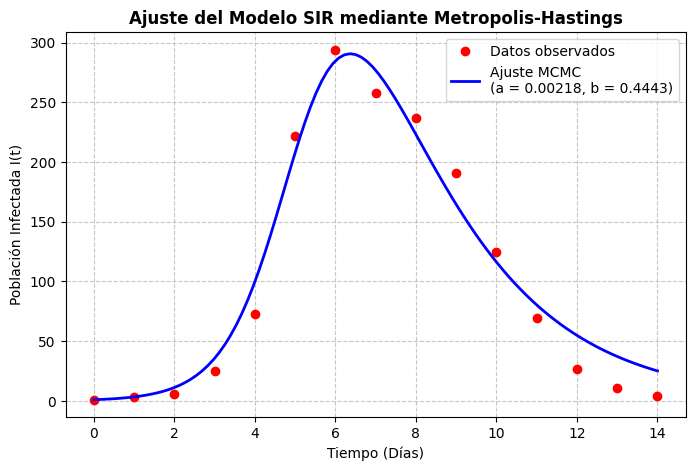

In [11]:

t_smooth = np.linspace(0, 14, 100)  # curva suave
I_fit = solve_sir(best_a, best_b, t_smooth)

#GRAFICAR DATOS VS. MODELO OPTIMIZADO
plt.figure(figsize=(8, 5))

# Puntos observados
plt.plot(t_data, I_data, 'ro', markersize=6, label='Datos observados')

# Curva ajustada por MCMC
plt.plot(
    t_smooth,
    I_fit,
    'b-',
    linewidth=2,
    label=f'Ajuste MCMC\n(a = {best_a:.5f}, b = {best_b:.4f})'
)

plt.title('Ajuste del Modelo SIR mediante Metropolis-Hastings', fontsize=12, fontweight='bold')
plt.xlabel('Tiempo (Días)', fontsize=10)
plt.ylabel('Población Infectada I(t)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()